# Phase 5: Exploratory Data Analysis (EDA)
This notebook analyzes the demand trends, wait times, seat utilization, revenues, and ratings using Pandas, Matplotlib, and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs('../reports/figures', exist_ok=True)
print("Environment initialized.")

Environment initialized.


## 1. Load Data

In [2]:
shops = pd.read_csv('../data/processed/shops.csv')
services = pd.read_csv('../data/processed/services.csv')
customers = pd.read_csv('../data/processed/customers.csv')
visits = pd.read_csv('../data/processed/visits.csv')
availability = pd.read_csv('../data/processed/availability.csv')
reviews = pd.read_csv('../data/processed/reviews.csv')

## 2. Demand Analysis by Hour and Day
Let's plot how customers arrive during the day.

C:\Users\PC\AppData\Local\Temp\ipykernel_27024\3519641057.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  visits['hour'] = pd.to_datetime(visits['arrival_time']).dt.hour


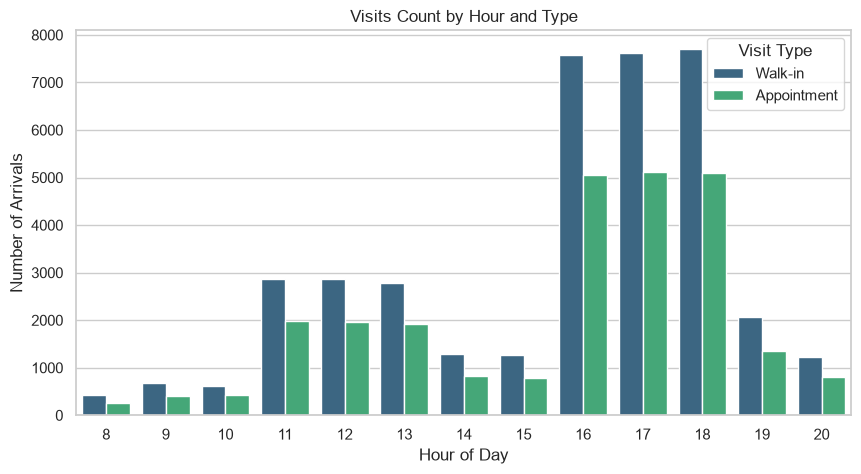

In [3]:
# Extact hour
visits['hour'] = pd.to_datetime(visits['arrival_time']).dt.hour
plt.figure(figsize=(10, 5))
sns.countplot(data=visits, x='hour', hue='visit_type', palette="viridis")
plt.title("Visits Count by Hour and Type")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Arrivals")
plt.legend(title="Visit Type")
plt.savefig('../reports/figures/demand_by_hour.png')
plt.show()

## 3. Waiting Time Distribution
Let's analyze customer wait times.

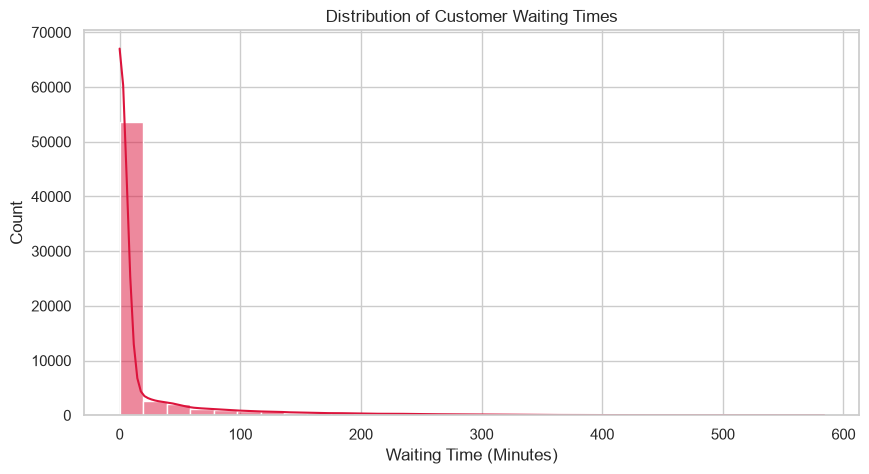

Median wait time: 0.0 mins
Mean wait time: 19.03 mins


In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(data=visits, x='waiting_time_minutes', kde=True, bins=30, color="crimson")
plt.title("Distribution of Customer Waiting Times")
plt.xlabel("Waiting Time (Minutes)")
plt.ylabel("Count")
plt.savefig('../reports/figures/waiting_time_dist.png')
plt.show()

print(f"Median wait time: {visits['waiting_time_minutes'].median()} mins")
print(f"Mean wait time: {visits['waiting_time_minutes'].mean():.2f} mins")

## 4. Seat Utilization
Formula: Seat Utilization = Occupied Seats / Total Seats * 100

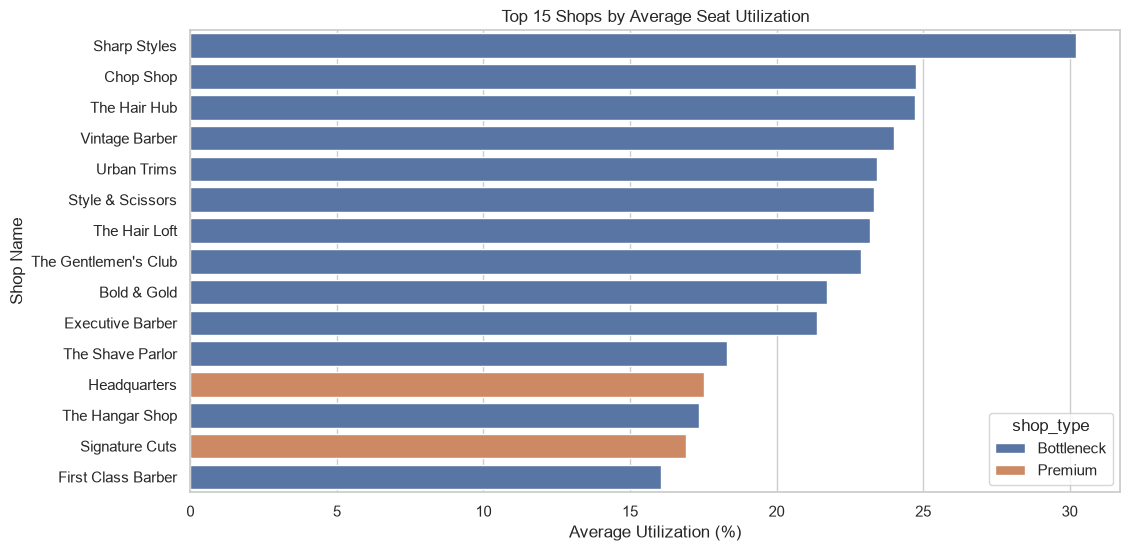

In [5]:
availability['utilization'] = (availability['occupied_seats'] / availability['total_seats']) * 100
avg_util = availability.groupby('shop_id')['utilization'].mean().reset_index()
avg_util = avg_util.merge(shops[['shop_id', 'shop_name', 'shop_type']], on='shop_id')

plt.figure(figsize=(12, 6))
sns.barplot(data=avg_util.sort_values(by='utilization', ascending=False).head(15), 
            x='utilization', y='shop_name', hue='shop_type', dodge=False)
plt.title("Top 15 Shops by Average Seat Utilization")
plt.xlabel("Average Utilization (%)")
plt.ylabel("Shop Name")
plt.savefig('../reports/figures/shop_utilization.png')
plt.show()

## 5. Revenue by Service Category

C:\Users\PC\AppData\Local\Temp\ipykernel_27024\1703623276.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=revenue_by_service.sort_values(by='revenue', ascending=False),


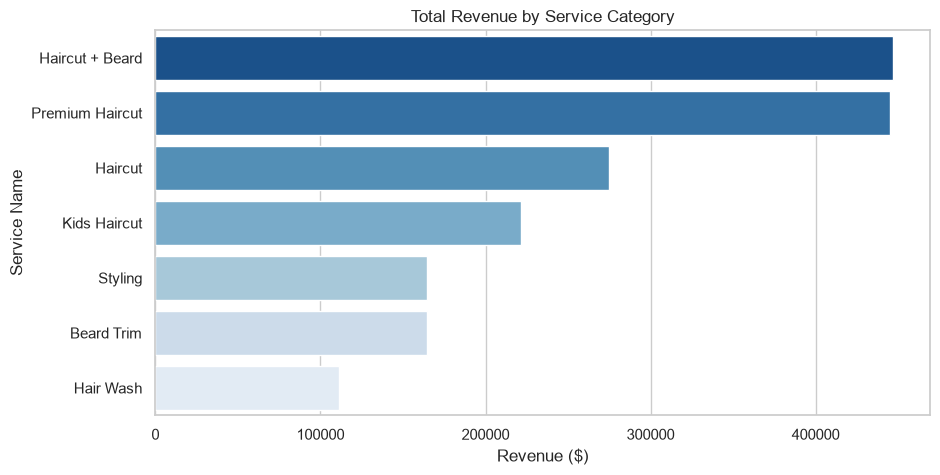

In [6]:
rev_data = visits.merge(services, on='service_id')
revenue_by_service = rev_data.groupby('service_name')['price'].sum().reset_index().rename(columns={'price': 'revenue'})

plt.figure(figsize=(10, 5))
sns.barplot(data=revenue_by_service.sort_values(by='revenue', ascending=False), 
            x='revenue', y='service_name', palette="Blues_r")
plt.title("Total Revenue by Service Category")
plt.xlabel("Revenue ($)")
plt.ylabel("Service Name")
plt.savefig('../reports/figures/revenue_by_service.png')
plt.show()

## 6. Ratings vs. Waiting Time
Does longer wait time degrade customer rating? Let's check.

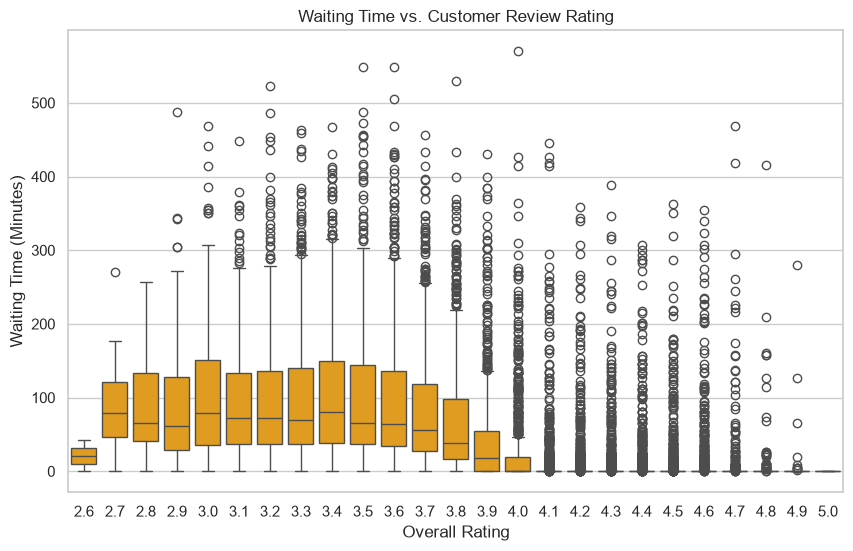

In [7]:
merged_reviews = reviews.merge(visits, on=['customer_id', 'shop_id'])
plt.figure(figsize=(10, 6))
sns.boxplot(data=merged_reviews, x='rating', y='waiting_time_minutes', color="orange")
plt.title("Waiting Time vs. Customer Review Rating")
plt.xlabel("Overall Rating")
plt.ylabel("Waiting Time (Minutes)")
plt.savefig('../reports/figures/rating_vs_wait_time.png')
plt.show()